# 01 · Exploración de los datos — Desempeño de las ventas

**Reto 1:** analizar el desempeño de las ventas y del personal de ventas (generación, tendencia, contribución y perfil para contratación).

Este notebook corresponde a la fase de **comprensión de los datos** de CRISP-DM. Aquí se revisa la calidad de las siete tablas, se toman las decisiones de limpieza y se buscan los patrones que guían el modelado. Las decisiones que salen de aquí se implementan en los pipelines de Kedro (`data_processing`, `feature_engineering` y `sales_analysis`), que son los que producen los resultados finales.

Los datos se leen desde el **catálogo de Kedro** (`conf/base/catalog.yml`), con las mismas rutas y opciones de lectura que los pipelines.

> Para ejecutarlo: copiar los CSV del curso en `data/01_raw/` y abrir el notebook con el kernel del entorno del proyecto.

**Contenido**
1. Carga de las tablas y validación de llaves
2. Faltantes, duplicados y columnas a recalcular
3. Distribuciones y outliers
4. Patrones de venta, vendedores y señal para el modelo
5. Conclusiones y decisiones de limpieza

## 1. Carga de las tablas y validación de llaves

Diagrama entidad-relación del dataset:

![ERD](../docs/erd.png)

In [1]:
import os
from pathlib import Path

import pandas as pd
from kedro.config import OmegaConfigLoader
from kedro.io import DataCatalog

# las rutas del catálogo son relativas a la raíz del proyecto
PROJECT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
os.chdir(PROJECT)

# catálogo del proyecto (mismas rutas y opciones de lectura que los pipelines)
config = OmegaConfigLoader(
    str(PROJECT / "conf"), base_env="base", default_run_env="local"
)
catalog = DataCatalog.from_config(config["catalog"])

pd.set_option("display.float_format", "{:,.2f}".format)

In [2]:
names = [
    "sales",
    "products",
    "categories",
    "employees",
    "customers",
    "cities",
    "countries",
]
raw = {name: catalog.load(f"raw_{name}") for name in names}

pd.DataFrame(
    {
        "filas": {n: len(df) for n, df in raw.items()},
        "columnas": {n: df.shape[1] for n, df in raw.items()},
        "memoria (MB)": {
            n: df.memory_usage(deep=True).sum() / 1e6 for n, df in raw.items()
        },
    }
)

,filas,columnas,memoria (MB)
sales,6758125,9,776.48
products,452,9,0.06
categories,11,2,0.00
employees,23,8,0.00
customers,98759,6,7.92
cities,96,4,0.00
countries,206,3,0.01


`sales` es la tabla de hechos: cada fila es una línea de venta, con el vendedor (`SalesPersonID`), el cliente, el producto, la cantidad, el descuento y la fecha. Las demás tablas son dimensiones. Para el Reto 1 las más importantes son **`employees`** (perfil del vendedor) y **`products`** (precio para calcular el ingreso).

In [3]:
sales = raw["sales"]
sales.head()

,SalesID,SalesPersonID,CustomerID,ProductID,Quantity,Discount,TotalPrice,SalesDate,TransactionNumber
0,1,6,27039,381,7,0.00,0.00,2018-02-05 07:38:25.430,FQL4S94E4ME1EZFTG42G
1,2,16,25011,61,7,0.00,0.00,2018-02-02 16:03:31.150,12UGLX40DJ1A5DTFBHB8
2,3,13,94024,23,24,0.00,0.00,2018-05-03 19:31:56.880,5DT8RCPL87KI5EORO7B0
3,4,8,73966,176,19,0.20,0.00,2018-04-07 14:43:55.420,R3DR9MLD5NR76VO17ULE
4,5,10,32653,310,9,0.00,0.00,2018-02-12 15:37:03.940,4BGS0Z5OMAZ8NDAFHHP3


In [4]:
sales.dtypes.to_frame("tipo").T

,SalesID,SalesPersonID,CustomerID,ProductID,Quantity,Discount,TotalPrice,SalesDate,TransactionNumber
tipo,int64,int64,int64,int64,int64,float64,float64,str,str


`SalesDate` viene como texto, así que hay que convertirla a fecha. Ahora se valida que cada llave foránea tenga correspondencia en su tabla de origen: una venta con un producto, cliente o vendedor inexistente no podría analizarse.

In [5]:
def orphans(child, child_key, parent, parent_key):
    # filas de child cuya llave no existe en parent
    return int((~child[child_key].isin(parent[parent_key])).sum())


checks = [
    ("sales.ProductID → products", sales, "ProductID", raw["products"], "ProductID"),
    (
        "sales.CustomerID → customers",
        sales,
        "CustomerID",
        raw["customers"],
        "CustomerID",
    ),
    (
        "sales.SalesPersonID → employees",
        sales,
        "SalesPersonID",
        raw["employees"],
        "EmployeeID",
    ),
    (
        "products.CategoryID → categories",
        raw["products"],
        "CategoryID",
        raw["categories"],
        "CategoryID",
    ),
    ("customers.CityID → cities", raw["customers"], "CityID", raw["cities"], "CityID"),
    ("employees.CityID → cities", raw["employees"], "CityID", raw["cities"], "CityID"),
    (
        "cities.CountryID → countries",
        raw["cities"],
        "CountryID",
        raw["countries"],
        "CountryID",
    ),
]
pd.DataFrame(
    [(name, orphans(c, ck, p, pk)) for name, c, ck, p, pk in checks],
    columns=["relación", "llaves huérfanas"],
)

,relación,llaves huérfanas
0,sales.ProductID → products,0
1,sales.CustomerID → customers,0
2,sales.SalesPersonID → employees,0
3,products.CategoryID → categories,0
4,customers.CityID → cities,0
5,employees.CityID → cities,0
6,cities.CountryID → countries,0


In [6]:
print(
    "Vendedores en ventas:",
    sales["SalesPersonID"].nunique(),
    "de",
    len(raw["employees"]),
)
print("Productos vendidos:", sales["ProductID"].nunique(), "de", len(raw["products"]))
print(
    "Clientes con compras:", sales["CustomerID"].nunique(), "de", len(raw["customers"])
)
print("Países con ciudades:", raw["cities"]["CountryID"].unique())

Vendedores en ventas: 23 de 23
Productos vendidos: 452 de 452
Clientes con compras: 98759 de 98759
Países con ciudades: [32]


**Hallazgos de la sección 1**

- Las relaciones están **completas**: no hay llaves huérfanas en ninguna tabla. Los 23 vendedores, los 452 productos y los 98,759 clientes aparecen en las ventas.
- Todas las ciudades pertenecen a **un solo país** (`CountryID` 32), así que un análisis por país no aporta. La dimensión geográfica útil es la ciudad.
- `SalesDate` hay que convertirla a fecha.
- **Decisión:** la validación de llaves se repite en cada ejecución del pipeline (`data_processing.build_sales_primary`), que se detiene con error si aparece una llave huérfana en datos futuros.

## 2. Faltantes, duplicados y columnas a recalcular

In [7]:
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

sns.set_theme(style="whitegrid")

missing = pd.concat(
    {
        name: pd.DataFrame(
            {"faltantes": df.isna().sum(), "% faltantes": 100 * df.isna().mean()}
        )
        for name, df in raw.items()
    }
)
missing[missing["faltantes"] > 0]

,,faltantes,% faltantes
sales,SalesDate,67526,1.00
customers,MiddleInitial,977,0.99


Solo hay faltantes explícitos en dos columnas: `sales.SalesDate` y `customers.MiddleInitial` (la inicial del segundo nombre, que no se usa). Las fechas faltantes son las importantes: el análisis de tendencias y el modelo dependen de ubicar cada venta en el tiempo.

Antes de decidir qué hacer con ellas se revisa si afectan más a algún vendedor o a algún periodo, porque si así fuera, descartarlas sesgaría la comparación.

Ventas sin fecha: 67,526 (1.00%)
Chi-cuadrado (¿se reparten igual que las ventas?): p = 0.009
% de sus ventas que pierde cada vendedor: entre 0.95% y 1.05%


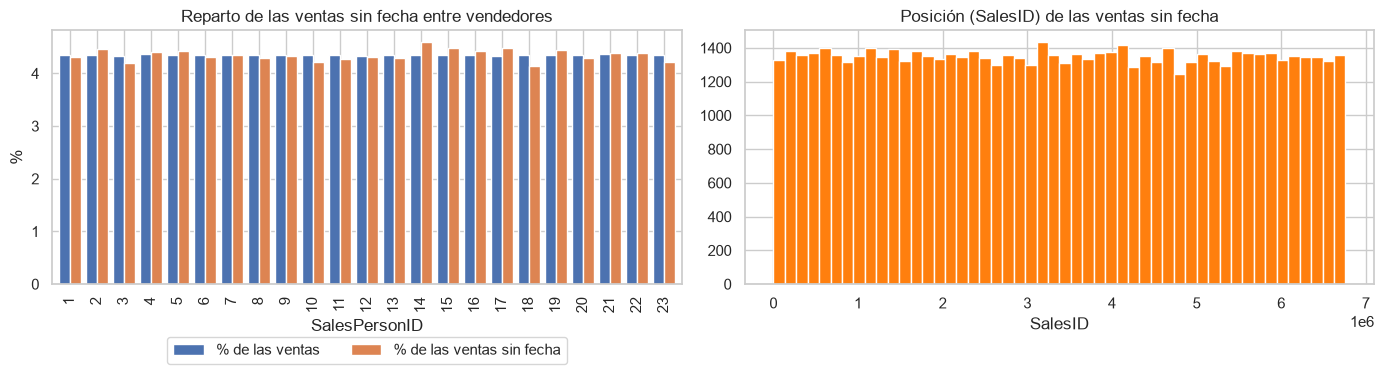

In [8]:
no_date = sales["SalesDate"].isna()
by_seller = pd.DataFrame(
    {
        "% de las ventas": 100 * sales["SalesPersonID"].value_counts(normalize=True),
        "% de las ventas sin fecha": 100
        * sales.loc[no_date, "SalesPersonID"].value_counts(normalize=True),
    }
).sort_index()

fig, axes = plt.subplots(1, 2, figsize=(14, 4))
by_seller.plot.bar(ax=axes[0], width=0.8)
axes[0].set_title("Reparto de las ventas sin fecha entre vendedores")
axes[0].set_xlabel("SalesPersonID")
axes[0].set_ylabel("%")
axes[0].legend(loc="upper center", bbox_to_anchor=(0.5, -0.18), ncol=2)
axes[1].hist(sales.loc[no_date, "SalesID"], bins=50, color="tab:orange")
axes[1].set_title("Posición (SalesID) de las ventas sin fecha")
axes[1].set_xlabel("SalesID")
fig.tight_layout()

chi2 = stats.chisquare(
    sales.loc[no_date, "SalesPersonID"].value_counts().sort_index(),
    sales["SalesPersonID"].value_counts(normalize=True).sort_index() * no_date.sum(),
)
print(f"Ventas sin fecha: {no_date.sum():,} ({100 * no_date.mean():.2f}%)")
print(f"Chi-cuadrado (¿se reparten igual que las ventas?): p = {chi2.pvalue:.3f}")

lost = (
    100
    * sales.loc[no_date, "SalesPersonID"].value_counts()
    / sales["SalesPersonID"].value_counts()
)
print(
    f"% de sus ventas que pierde cada vendedor: entre {lost.min():.2f}% y {lost.max():.2f}%"
)

Las ventas sin fecha (1%) aparecen a lo largo de toda la tabla, no en un periodo concreto. Con tantas filas, el chi-cuadrado detecta que el reparto entre vendedores **no es exactamente** proporcional (p = 0.009), pero la diferencia es pequeña: cada vendedor pierde entre ~0.95% y ~1.05% de sus ventas. Eso es mucho menor que la brecha de ~2% entre el mejor y el peor vendedor, así que **descartarlas no cambia la comparación**. Imputar una fecha inventada sería peor que descartarlas.

Ahora los duplicados, por fila completa y por identificador:

In [9]:
dups = pd.DataFrame(
    {
        "filas duplicadas": {n: int(df.duplicated().sum()) for n, df in raw.items()},
        "IDs duplicados": {
            n: int(df.iloc[:, 0].duplicated().sum()) for n, df in raw.items()
        },
    }
)
print(
    "TransactionNumber duplicados en sales:",
    sales["TransactionNumber"].duplicated().sum(),
)
dups

TransactionNumber duplicados en sales: 0


,filas duplicadas,IDs duplicados
sales,0,0
products,0,0
categories,0,0
employees,0,0
customers,0,0
cities,0,0
countries,0,0


No hay duplicados en ninguna tabla, y cada `TransactionNumber` es único: **cada fila de `sales` es una transacción distinta** (no hay canastas con varias líneas).

### `TotalPrice`: una columna que hay que recalcular

In [10]:
print(sales["TotalPrice"].describe())
print("\n% de filas con TotalPrice = 0:", 100 * (sales["TotalPrice"] == 0).mean())

count   6,758,125.00
mean            0.00
std             0.00
min             0.00
25%             0.00
50%             0.00
75%             0.00
max             0.00
Name: TotalPrice, dtype: float64

% de filas con TotalPrice = 0: 100.0


`TotalPrice` está en **0 en el 100% de las filas**, así que no sirve para medir ventas. Se recalcula con el precio del producto:

$$\text{Revenue} = \text{Price} \times \text{Quantity} \times (1 - \text{Discount})$$

In [11]:
products = raw["products"]
check = sales.head(5).merge(products[["ProductID", "Price"]], on="ProductID")
check["Revenue"] = check["Price"] * check["Quantity"] * (1 - check["Discount"])
check[
    ["SalesID", "ProductID", "Price", "Quantity", "Discount", "TotalPrice", "Revenue"]
]

,SalesID,ProductID,Price,Quantity,Discount,TotalPrice,Revenue
0,1,381,44.23,7,0.00,0.00,309.64
1,2,61,62.55,7,0.00,0.00,437.82
2,3,23,79.02,24,0.00,0.00,"1,896.44"
3,4,176,81.32,19,0.20,0.00,"1,236.01"
4,5,310,79.98,9,0.00,0.00,719.80


### Faltantes "escondidos" y lectura de códigos

In [12]:
default = pd.read_csv("data/01_raw/countries.csv")
print("Leído con las opciones por defecto de pandas:")
print(default[default["CountryCode"].isna()])
print("\nLeído con el catálogo (keep_default_na: false):")
print(raw["countries"][raw["countries"]["CountryName"] == "Australia"])

Leído con las opciones por defecto de pandas:
     CountryID CountryName CountryCode
145        146   Australia         NaN

Leído con el catálogo (keep_default_na: false):
     CountryID CountryName CountryCode
145        146   Australia          NA


In [13]:
for col in ["Class", "Resistant", "IsAllergic"]:
    print(products[col].value_counts().to_dict())
print(
    "VitalityDays = 0:",
    f"{100 * (products['VitalityDays'] == 0).mean():.0f}% de los productos",
)

{'Medium': 156, 'Low': 153, 'High': 143}
{'Durable': 164, 'Weak': 148, 'Unknown': 140}
{'False': 165, 'True': 157, 'Unknown': 130}
VitalityDays = 0: 61% de los productos


**Hallazgos de la sección 2**

| Problema | Decisión |
|---|---|
| `TotalPrice` = 0 en todas las filas | Se elimina y se recalcula `Revenue = Price × Quantity × (1 − Discount)` (`clean_sales` y `build_sales_primary`). |
| 67,526 ventas (1%) sin `SalesDate` | Se descartan (`clean_sales`). Cada vendedor pierde entre ~0.95% y ~1.05% de sus ventas, un efecto mucho menor que las diferencias entre vendedores. |
| `CountryCode` de Australia es `"NA"` | No es un faltante: el catálogo lo lee con `keep_default_na: false`. |
| `MiddleInitial` vacía en 977 clientes | Se ignora: no se usa en el análisis. |
| `Resistant` e `IsAllergic` con valor `"Unknown"`, y `VitalityDays` en 0 para el 61% de los productos | Son faltantes "escondidos", pero son atributos de producto que no se usan en el Reto 1. Se dejan como están. |
| Duplicados | No hay. De todas formas, el pipeline los elimina por `SalesID` y `TransactionNumber` si aparecen en datos futuros. |